In [1]:
from google.colab import drive
drive.mount('/content/drive')

# 2) Define where the project lives on Drive
DRIVE_PROJECT_ROOT = '/content/drive/MyDrive/DetectIllegalParking'

# 3) Make the target directories in /content
!mkdir -p /content/yolo_car_detection
!mkdir -p /content/dataset/images

# 4) Copy the YOLO code + configs + weights + names
!cp $DRIVE_PROJECT_ROOT/yolo_car_detection/detect_yolov3.py   /content/yolo_car_detection/
!cp $DRIVE_PROJECT_ROOT/yolo_car_detection/yolov3.cfg         /content/yolo_car_detection/
!cp $DRIVE_PROJECT_ROOT/yolo_car_detection/yolov3.weights     /content/yolo_car_detection/
!cp $DRIVE_PROJECT_ROOT/yolo_car_detection/coco.names         /content/yolo_car_detection/
!cp $DRIVE_PROJECT_ROOT/yolo_car_detection/detect_MiDaS.py    /content/yolo_car_detection/

# 5) Copy segmentation model
!cp $DRIVE_PROJECT_ROOT/seg_cpu.pt         /content/

!cp -r $DRIVE_PROJECT_ROOT/frankfurt/*       /content/dataset/images

Mounted at /content/drive


In [ ]:
!touch /content/yolo_car_detection/__init__.py

/usr/local/lib/python3.11/dist-packages/torch/hub.py:330: UserWarning: You are about to download and run code from an untrusted repository. In a future release, this won't be allowed. To add the repository to your trusted list, change the command to {calling_fn}(..., trust_repo=False) and a command prompt will appear asking for an explicit confirmation of trust, or load(..., trust_repo=True), which will assume that the prompt is to be answered with 'yes'. You can also use load(..., trust_repo='check') which will only prompt for confirmation if the repo is not already trusted. This will eventually be the default behaviour
  warnings.warn(
Downloading: "https://github.com/intel-isl/MiDaS/zipball/master" to /root/.cache/torch/hub/master.zip
/usr/local/lib/python3.11/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.l

Loading weights:  None


/usr/local/lib/python3.11/dist-packages/torch/hub.py:330: UserWarning: You are about to download and run code from an untrusted repository. In a future release, this won't be allowed. To add the repository to your trusted list, change the command to {calling_fn}(..., trust_repo=False) and a command prompt will appear asking for an explicit confirmation of trust, or load(..., trust_repo=True), which will assume that the prompt is to be answered with 'yes'. You can also use load(..., trust_repo='check') which will only prompt for confirmation if the repo is not already trusted. This will eventually be the default behaviour
  warnings.warn(
Downloading: "https://github.com/rwightman/gen-efficientnet-pytorch/zipball/master" to /root/.cache/torch/hub/master.zip
Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-weights/tf_efficientnet_lite3-b733e338.pth" to /root/.cache/torch/hub/checkpoints/tf_efficientnet_lite3-b733e338.pth
Downloading: "https://github.

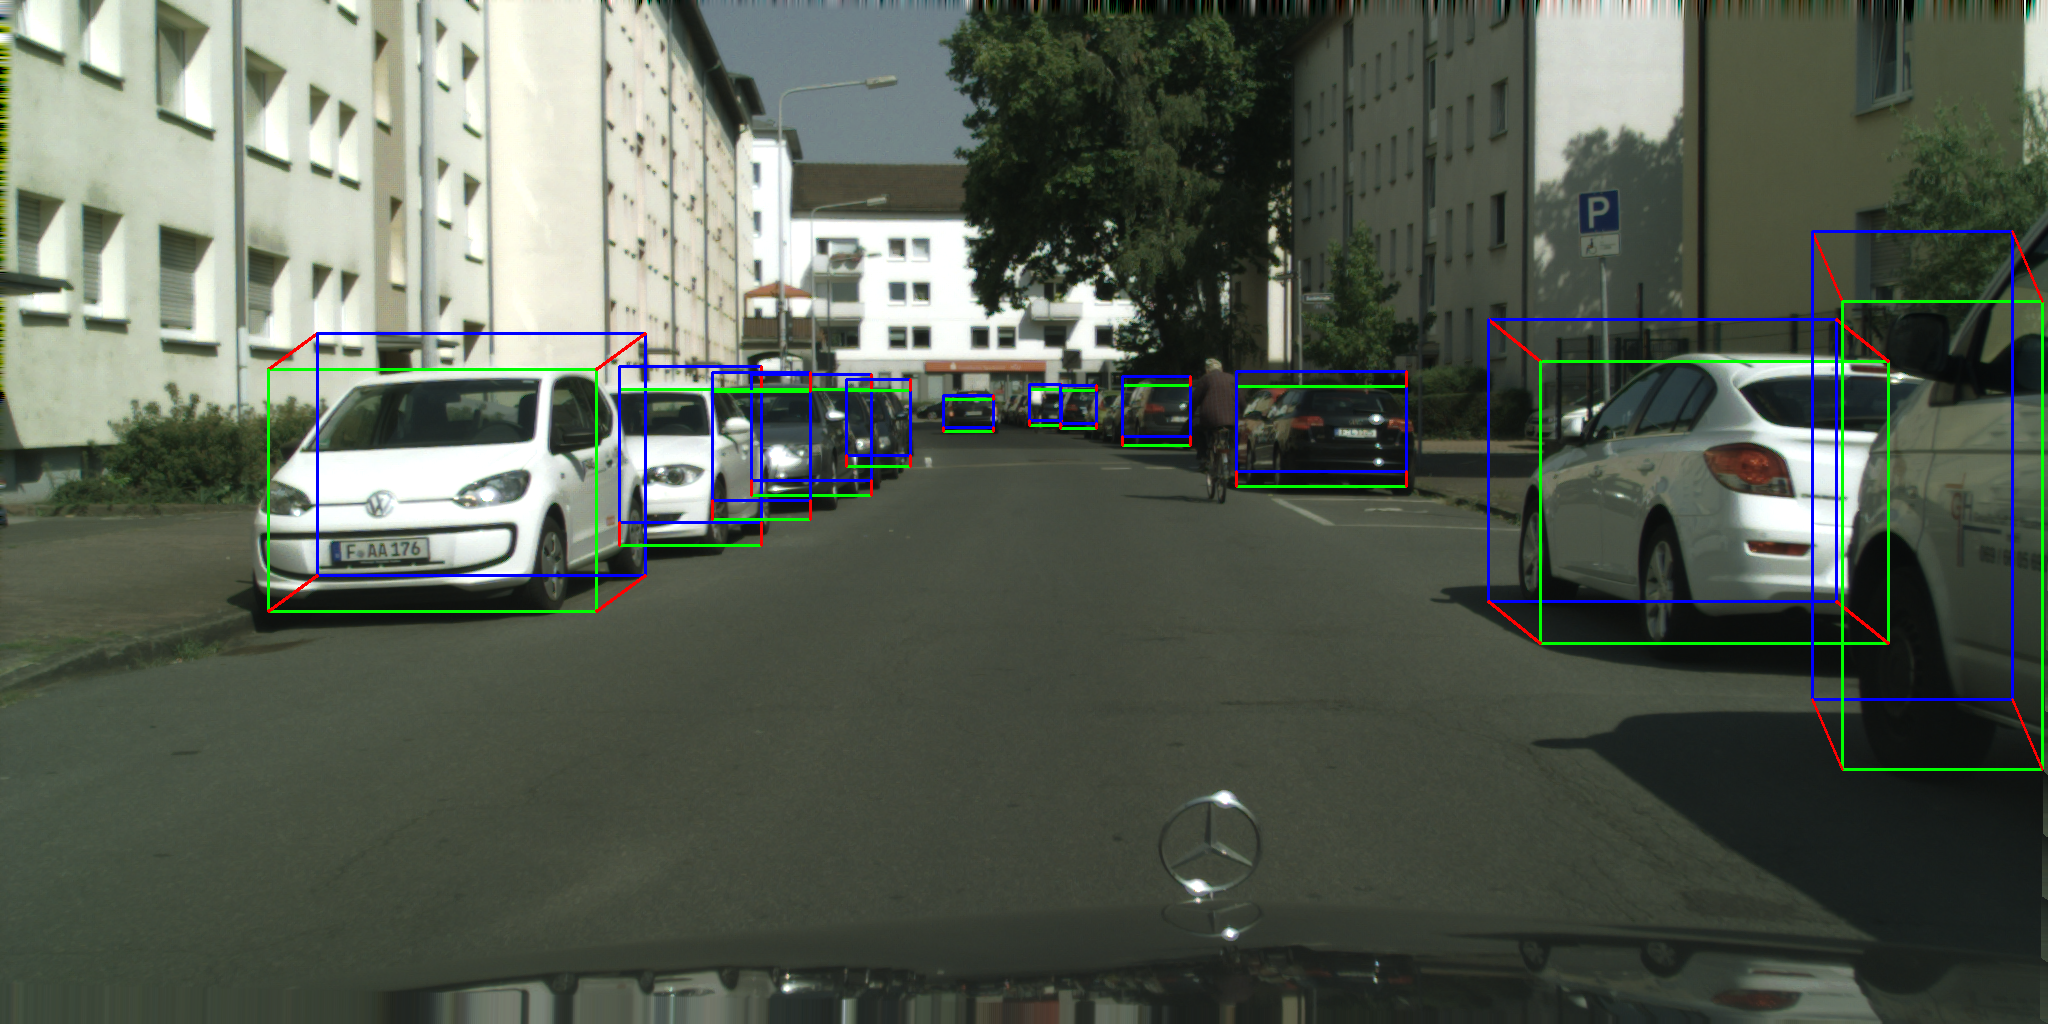

In [ ]:
#### Object Detection and 3D Bounding Boxes ####
import os
os.chdir('/content')
from google.colab.patches import cv2_imshow
import numpy as np
import cv2

from yolo_car_detection.detect_yolov3 import detect_objects
from yolo_car_detection.detect_MiDaS import estimate_depth

# Load image
image_path = "/content/dataset/images/frankfurt_000000_000576_leftImg8bit.png"
frame = cv2.imread(image_path)
image_height, image_width = frame.shape[:2]

# Get 2D bounding boxes
detections = detect_objects(frame)

# Get depth map
depth_map = estimate_depth(frame)

# Draw pseudo-3D bounding boxes
def draw_3d_bbox(img, bbox, depth, img_width, scale=0.5):
    x1, y1, x2, y2 = bbox
    w = x2 - x1
    h = y2 - y1

    # Crop to central 80% of area
    shrink_factor = 0.894
    new_w = int(w * shrink_factor)
    new_h = int(h * shrink_factor)
    cx = int((x1 + x2) / 2)
    cy = int((y1 + y2) / 2)
    x1 = cx - new_w // 2
    x2 = cx + new_w // 2
    y1 = cy - new_h // 2
    y2 = cy + new_h // 2

    w = x2 - x1
    h = y2 - y1

    # Compute object horizontal position
    center_x = cx
    if center_x < img_width / 3:
        dx = int(w * 0.15)
    elif center_x > 2 * img_width / 3:
        dx = -int(w * 0.15)
    else:
        dx = 0

    dy = int(h * 0.15)
    dz = int(depth * scale)

    front = np.array([
        [x1, y1], [x2, y1], [x2, y2], [x1, y2]
    ])
    back = np.array([
        [x1 + dx, y1 - dy - dz],
        [x2 + dx, y1 - dy - dz],
        [x2 + dx, y2 - dy - dz],
        [x1 + dx, y2 - dy - dz]
    ])

    # Draw front and back faces
    for i in range(4):
        cv2.line(img, tuple(front[i]), tuple(front[(i + 1) % 4]), (0, 255, 0), 2)
        cv2.line(img, tuple(back[i]), tuple(back[(i + 1) % 4]), (255, 0, 0), 2)
        cv2.line(img, tuple(front[i]), tuple(back[i]), (0, 0, 255), 2)

# Loop through detections and draw 3D boxes
for bbox in detections:
    x1, y1, x2, y2, cls_id, conf = bbox

    # Extract object depth from center
    center_x = int((x1 + x2) / 2)
    center_y = int((y1 + y2) / 2)
    if 0 <= center_y < depth_map.shape[0] and 0 <= center_x < depth_map.shape[1]:
        object_depth = float(depth_map[center_y, center_x])
    else:
        object_depth = 0.0

    # Draw 3D box
    draw_3d_bbox(frame, (x1, y1, x2, y2), object_depth, image_width)

# Show result
cv2_imshow(frame)

In [ ]:
########## Inference Code for Segmentation to Generate Image Masks ############
%%bash
cat > run_segmentation.py << 'EOF'
import os
import argparse
import torch
import numpy as np
from PIL import Image

# color map for [bg, road, sidewalk, parking]
COLORS = np.array([
    [  0,   0,   0],
    [128,  64, 128],
    [244,  35, 232],
    [220,  20,  60],
], dtype=np.uint8)

def preprocess(img: Image.Image, target_size=(512,1024)):
    img = img.convert("RGB").resize(target_size, Image.BILINEAR)
    arr = np.array(img).astype(np.float32)/255.0
    mean = np.array([0.485,0.456,0.406],dtype=np.float32)
    std  = np.array([0.229,0.224,0.225],dtype=np.float32)
    arr = (arr-mean)/std
    tensor = torch.from_numpy(arr.transpose(2,0,1)).unsqueeze(0)
    return tensor

def decode_mask(mask: np.ndarray):
    color_mask = COLORS[mask]
    return Image.fromarray(color_mask)

def overlay(image: Image.Image, mask: Image.Image, alpha=0.5):
    return Image.blend(image.convert("RGBA"), mask.convert("RGBA"), alpha)

def run_one(model, path, out_dir):
    img = Image.open(path)
    inp = preprocess(img)
    with torch.no_grad():
        preds = model(inp)              # [1,4,H,W]
        mask = preds.argmax(1).squeeze(0).cpu().numpy().astype(np.uint8)
    base = os.path.splitext(os.path.basename(path))[0]
    # save the color mask and overlay
    cm = decode_mask(mask).resize(img.size, Image.NEAREST)
    ov = overlay(img, cm, alpha=0.5)
    cm.save(os.path.join(out_dir, f"{base}_mask.png"))
    # note that overlay is not being used in the following steps, it is saved just for visualizaiton of the predictions
    ov.save(os.path.join(out_dir, f"{base}_overlay.png"))
    print(f"✓ {base}")

if __name__=="__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--model",    required=True,
                   help="path to seg_cpu.pt")
    p.add_argument("--input",    required=True, nargs="+",
                   help="one or more input image files")
    p.add_argument("--output-dir", default="outputs",
                   help="where to save masks & overlays")
    args = p.parse_args()

    os.makedirs(args.output_dir, exist_ok=True)
    model = torch.jit.load(args.model, map_location="cpu").eval()

    for img_path in args.input:
        run_one(model, img_path, args.output_dir)
EOF

In [ ]:
#### Executing Inference Code ####
#### Generates Masks, and Overlay for Every Image Under Dataset/Images ####
### Can Be Executable on Single Images, Copy the Path to Image Into Input Argument ####
!mkdir -p /content/dataset/masks
!python3 run_segmentation.py \
   --model /content/seg_cpu.pt \
   --input /content/dataset/images/*.png \
   --output-dir /content/dataset/masks

✓ lindau_000039_000019_leftImg8bit


In [ ]:
#### Computing Overlapping Bottom Surface Area of the Vehicles ####
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import glob
import os
from yolo_car_detection.detect_yolov3 import detect_objects
from yolo_car_detection.detect_MiDaS import estimate_depth

RESULTS_DIR = "/content/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# — helpers  —
def get_bottom_polygon(bbox, depth, img_width, shrink_factor=0.894, scale=0.5):
    x1,y1,x2,y2 = bbox
    w, h = x2-x1, y2-y1
    nw, nh = int(w*shrink_factor), int(h*shrink_factor)
    cx, cy = (x1+x2)//2, (y1+y2)//2
    x1s, x2s = cx-nw//2, cx+nw//2
    y1s, y2s = cy-nh//2, cy+nh//2
    w, h = x2s-x1s, y2s-y1s

    if   cx <  img_width/3: dx =  int(w*0.15)
    elif cx > 2*img_width/3: dx = -int(w*0.15)
    else:                    dx = 0

    dy = int(h*0.15)
    dz = 0

    front_bl = (x1s, y2s)
    front_br = (x2s, y2s)
    back_br  = (x2s+dx, y2s-dy-dz)
    back_bl  = (x1s+dx, y2s-dy-dz)
    return np.array([front_bl, front_br, back_br, back_bl], dtype=np.int32)

def compute_overlap(poly, seg_mask, class_ids=(1,2,3)):
    h, w = seg_mask.shape
    raster = np.zeros((h,w), np.uint8)
    cv2.fillPoly(raster, [poly], 1)
    total = int(raster.sum())
    out = {}
    for cid in class_ids:
        if total>0:
            cnt = int(((seg_mask==cid) & (raster==1)).sum())
            out[cid] = (cnt, cnt/total)
        else:
            out[cid] = (0, 0.0)
    return out

def load_id_mask(mask_path):
    # read BGR, convert to RGB so our COLORS[] matches
    bgr = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    if bgr.ndim==3:
        cm = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    else:
        return bgr
    h,w,_ = cm.shape
    idm = np.zeros((h,w), np.uint8)
    COLORS = np.array([
      [  0,   0,   0],
      [128,  64, 128],
      [244,  35, 232],
      [220,  20,  60],
    ], np.uint8)
    for cid,col in enumerate(COLORS):
        idm[np.all(cm==col,axis=-1)] = cid
    return idm


# — point these at either a file or a folder —
IMAGE_SOURCE = "/content/dataset/images"   # or in format of "/content/dataset/images/my.png"
MASK_SOURCE  = "/content/dataset/masks"    # or in format of "/content/dataset/masks/my_mask.png"

# build list of img paths
if os.path.isdir(IMAGE_SOURCE):
    image_paths = sorted(glob.glob(os.path.join(IMAGE_SOURCE, "*.png")))
else:
    image_paths = [IMAGE_SOURCE]

for img_path in image_paths:
    # derive mask path
    base = os.path.basename(img_path).rsplit(".png",1)[0]
    if os.path.isdir(MASK_SOURCE):
        mask_path = os.path.join(MASK_SOURCE, f"{base}_mask.png")
    else:
        mask_path = MASK_SOURCE

    frame = cv2.imread(img_path)
    seg_mask = load_id_mask(mask_path)

    # 2) detection & depth
    detections = detect_objects(frame)
    depth_map  = estimate_depth(frame)

    # 3) build segmentation overlay
    COLORS_RGB = np.array([[0,0,0],[128,64,128],[244,35,232],[220,20,60]],np.uint8)
    color_seg  = np.zeros_like(frame)
    for cid, col in enumerate(COLORS_RGB):
        color_seg[seg_mask==cid] = col
    overlay = cv2.addWeighted(frame, 0.5, color_seg, 0.5, 0)

    # 4) per-car loop
    FONT       = cv2.FONT_HERSHEY_SIMPLEX
    BOX_COLOR  = (0,255,0)
    POLY_COLOR = (0,0,255)
    TXT_COLOR  = (255,255,255)

    H, W = frame.shape[:2]
    for x1,y1,x2,y2, cls_id, conf in detections:
        # draw 2D box
        cv2.rectangle(overlay, (x1,y1), (x2,y2), BOX_COLOR, 2)

        # bottom poly
        cx, cy = (x1+x2)//2, (y1+y2)//2
        d      = float(depth_map[cy, cx]) if 0<=cy<H else 0.0
        poly   = get_bottom_polygon((x1,y1,x2,y2), d, W)

        # overlap
        ov           = compute_overlap(poly, seg_mask, (1,2,3))
        road_pct     = ov[1][1]
        sidewalk_pct = ov[2][1]
        park_pct     = ov[3][1]

        # decide mixed
        present = {cid for cid,p in [(1,road_pct),(2,sidewalk_pct),(3,park_pct)] if p>0}
        if 1 in present and len(present)>1:
            cv2.polylines(overlay, [poly], True, POLY_COLOR, 2)
            label = f"road: {road_pct:.0%}"
            ty    = y1-10 if y1>20 else y1+20
            cv2.putText(overlay, label, (x1,ty), FONT, 0.5, TXT_COLOR, 1, cv2.LINE_AA)

    # 5) show result
    print("▶", base)
    cv2_imshow(overlay)
    # save to results folder
    out_path = os.path.join(RESULTS_DIR, f"{base}_result.png")
    cv2.imwrite(out_path, overlay)
    print("Saved result to", out_path)